# Kostenorientierte Klassifikation von Maschinenausfällen

**Gruppenarbeit Classification · Business Intelligence · WiSe 2026/27**  
Technische Hochschule Mannheim · Gruppe: [Gruppenname] · Mitglieder: [Jannika Julia Heckmann, Felix Bauer, Anita Kopp, Jason Neufeld]

Ziel ist die Vorhersage von Maschinenfehlschlägen unter der Kostenfunktion **FP + 6 × FN**. Untersucht wird ein Hybridmodell aus physikalischen Regeln und einer logistischen Regression für das verbleibende Verschleißrisiko.

**Reproduktion.** Das Notebook enthält den vollständigen Modellcode und verwendet die bereitgestellten Dateien modeling.csv und challenge.csv. Die Konfiguration und der Gruppenname für den CSV-Export stehen in der ersten Codezelle. Für die Ausführung werden NumPy, pandas und scikit-learn benötigt.

In [13]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

GRUPPENNAME = "GRUPPENNAME"
DATENORDNER = Path(".") 
if not (DATENORDNER / "modeling.csv").is_file():
    DATENORDNER = Path.home() / "Downloads"
AUSGABEORDNER = Path("results")

TARGET = "Machine failure"
FEATURES = ["Type", "Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
TYP = {"L": 0, "M": 1, "H": 2}
KOSTEN_FN = 6
SCHWELLE = 1 / (1 + KOSTEN_FN)
SEEDS = (2006, 2026, 2007, 888, 1024)

## 1 · Explorative Datenanalyse

Der beschriftete Datensatz umfasst **8.000 Produktionsvorgänge**, davon **271 Ausfälle (3,39 %)**. Geprüft werden das Eingabeschema, die Gültigkeit der Sensorwerte, die Zielklassen und doppelte Merkmalszeilen. Die folgende Auswertung beschreibt die Ausfallhäufigkeit nach Produktvariante und die Verteilung der numerischen Merkmale. Extreme Messwerte bleiben als potenziell relevante Ausfallsignale erhalten.

In [14]:
def csv_lesen(pfad, mit_labels=False):
    if not pfad.is_file():
        raise FileNotFoundError(f"{pfad} fehlt. Prüfe DATENORDNER in der ersten Zelle.")
    daten = pd.read_csv(pfad, float_precision="round_trip")
    erwartet = FEATURES + ([TARGET] if mit_labels else [])
    if daten.empty or set(daten.columns) != set(erwartet):
        raise ValueError(f"{pfad}: Erwartete Spalten: {erwartet}")
    if not daten["Type"].isin(TYP).all() or not np.isfinite(daten[FEATURES[1:]].to_numpy(float)).all():
        raise ValueError(f"{pfad}: Ungültige Messwerte oder Produktvarianten.")
    if mit_labels and set(daten[TARGET].unique()) != {0, 1}:
        raise ValueError(f"{pfad}: Die Zielspalte muss beide Klassen 0 und 1 enthalten.")
    return daten

daten = csv_lesen(DATENORDNER / "modeling.csv", mit_labels=True)
X, y = daten[FEATURES], daten[TARGET].to_numpy(dtype=int)
print(f"{len(y)} Vorgänge | {y.sum()} Ausfälle ({y.mean():.2%}) | {X.duplicated().sum()} doppelte Merkmalszeilen")
varianten = daten.groupby("Type")[TARGET].agg(Vorgänge="size", Ausfälle="sum")
display(varianten.assign(Ausfallquote_Prozent=100 * varianten["Ausfälle"] / varianten["Vorgänge"]).round(2))
display(X[FEATURES[1:]].describe().round(2))

8000 Vorgänge | 271 Ausfälle (3.39%) | 0 doppelte Merkmalszeilen


,Vorgänge,Ausfälle,Ausfallquote_Prozent
Type,,,
H,795,18,2.26
L,4808,184,3.83
M,2397,69,2.88


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,8000.00,8000.00,8000.00,8000.00,8000.00
mean,300.00,310.00,1538.33,40.00,107.84
std,1.99,1.48,178.48,9.95,63.65
min,295.30,305.70,1181.00,3.80,0.00
25%,298.30,308.80,1423.00,33.20,53.00
50%,300.10,310.10,1503.00,40.10,108.00
75%,301.50,311.10,1611.00,46.70,162.00
max,304.50,313.80,2886.00,76.60,253.00


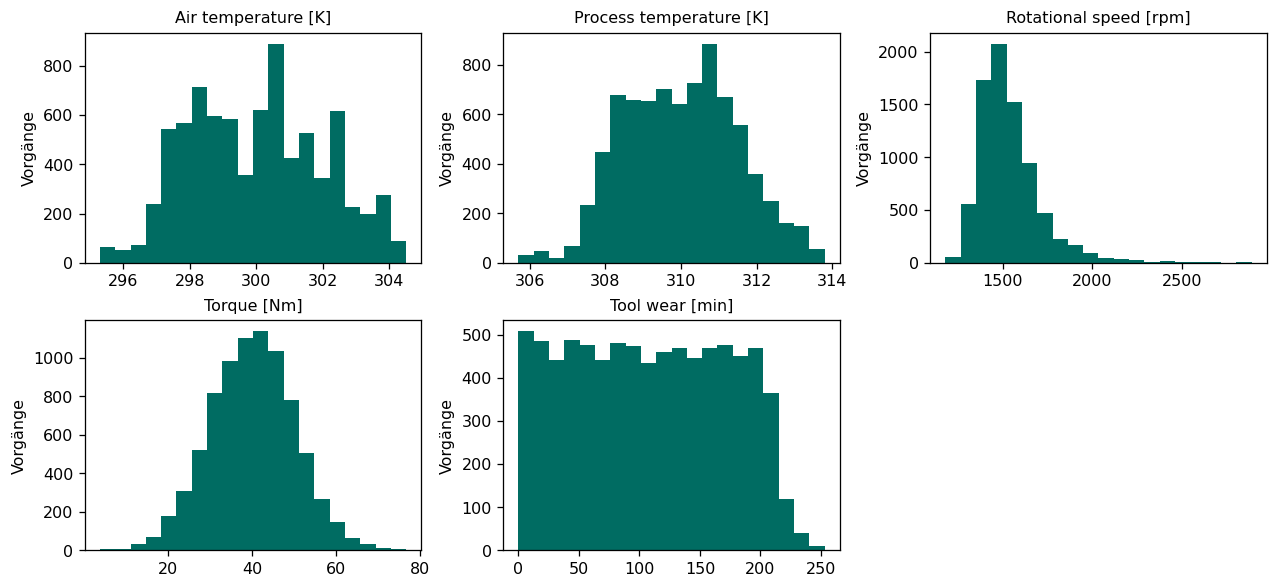

In [15]:
try:
    from matplotlib.figure import Figure
except ModuleNotFoundError as error:
    if error.name != "matplotlib":
        raise
    Figure = None

def diagramm_anzeigen(fig):
    from io import BytesIO
    from IPython.display import Image

    bild = BytesIO()
    fig.savefig(bild, format="png", dpi=115, bbox_inches="tight")
    display(Image(data=bild.getvalue()))

if Figure is None:
    print("Für neu gerenderte Diagramme: %pip install matplotlib. Die Tabellen bleiben verfügbar.")
else:
    fig = Figure(figsize=(11, 5), layout="constrained")
    axes = fig.subplots(2, 3)
    for ax, spalte in zip(axes.flat, FEATURES[1:]):
        ax.hist(daten[spalte], bins=20, color="#006C62")
        ax.set_title(spalte, fontsize=10)
        ax.set_ylabel("Vorgänge")
    axes.flat[-1].set_visible(False)
    diagramm_anzeigen(fig)


## 2 · Trennung von Training und Prüfung

Die festgelegte Modellkonfiguration wird mit **fünf Wiederholungen einer stratifizierten fünffachen Kreuzvalidierung** bewertet. Pro Falte werden alle Modellparameter ausschließlich aus den Trainingszeilen gelernt. Jede Zeile liefert pro Wiederholung genau eine Vorhersage auf einer Prüffalte. Der Vergleich nutzt dieselben Aufteilungen für alle Varianten. Die Wiederholungen erfassen die Empfindlichkeit gegenüber der Aufteilung derselben Kohorte.

In [16]:
def falten(seed):
    return StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(X, y)

train, pruefung = next(falten(SEEDS[0]))
print(f"Beispielfalte: {len(train)} Vorgänge im Training, {len(pruefung)} in der Prüfung")

Beispielfalte: 6400 Vorgänge im Training, 1600 in der Prüfung


## 3 · Merkmalsaufbereitung

Drei physikalisch motivierte Merkmale ergänzen die Sensorwerte: die mechanische Leistung $P=M\,2\pi n/60$, der Temperaturabstand zwischen Prozess und Umgebung sowie das Produkt aus Werkzeugstandzeit und Drehmoment als Belastungsindikator. Für die Kühlungsregel wird der Temperaturabstand gemeinsam mit der Drehzahl ausgewertet. Die Produktvarianten L, M und H gehen als geordnete Stufen in das Modell ein.

In [17]:
def merkmale(frame):
    drehzahl = frame["Rotational speed [rpm]"].to_numpy(float)
    moment = frame["Torque [Nm]"].to_numpy(float)
    standzeit = frame["Tool wear [min]"].to_numpy(float)
    abstand = frame["Process temperature [K]"].to_numpy(float) - frame["Air temperature [K]"].to_numpy(float)
    leistung = drehzahl * moment * (2 * np.pi / 60)
    typ = frame["Type"].map(TYP).to_numpy()
    return leistung, abstand, drehzahl, standzeit * moment, typ

## 4 · Physikalischer Regelkern

Die Regelsuche maximiert die Anzahl erfasster Trainingsausfälle in Bereichen ohne Fehlalarm. Für die Leistung werden eine untere und eine obere Grenze gelernt. Die Kühlungsregel kombiniert einen niedrigen Temperaturabstand mit niedriger Drehzahl. Die Belastungsregel schätzt einen gemeinsamen Grundwert und einen Abstand zwischen den Produktstufen. Die Grenzsuche wird je Trainingsfalte wiederholt. Die hohe Präzision bei der Regelsuche ist ein Trainingskriterium. Die Leistung auf ungesehenen Fällen wird in Abschnitt 6 berichtet.

In [18]:
def schnitt(von, bis, raster):
    for einheit in raster:
        kandidat = (np.floor(von / einheit) + 1) * einheit
        if von < kandidat <= bis:
            return kandidat
    return max(von + (bis - von) / 2, np.nextafter(von, bis))

def untergrenze(werte, ziel, raster):
    normal = werte[ziel == 0]
    erster_normaler = normal.min() if len(normal) else np.inf
    treffer = werte[(ziel == 1) & (werte < erster_normaler)]
    if not len(treffer):
        return -np.inf, 0
    grenze = schnitt(treffer.max(), erster_normaler, raster) if len(normal) else np.inf
    return grenze, len(treffer)

def kuehlgrenzen(abstand, drehzahl, ziel):
    kandidaten = np.unique(abstand)
    bestes_paar, beste_treffer = (-np.inf, -np.inf), 0
    for i, wert in enumerate(kandidaten):
        innen = abstand <= wert
        rpm, treffer = untergrenze(drehzahl[innen], ziel[innen], (10, 1))
        if treffer > beste_treffer:
            naechster = kandidaten[i + 1] if i + 1 < len(kandidaten) else np.inf
            bestes_paar, beste_treffer = (schnitt(wert, naechster, (0.1,)), rpm), treffer
    return bestes_paar

def belastungsgrenzen(last, typ, ziel):
    abstaende = sorted(range(0, 3001, 100), key=lambda a: (a % 1000 != 0, a % 500 != 0, a))
    beste_treffer = -1
    for abstand in abstaende:
        grenze, treffer = untergrenze(abstand * typ - last, ziel, (1000, 100, 10))
        if treffer > beste_treffer:
            grenzen, beste_treffer = -grenze + abstand * np.arange(len(TYP)), treffer
    return grenzen

In [19]:
# MODELLBEGINN: Physikalische Regeln für Leistung, Kühlung und Werkzeugbelastung.
def regeln_lernen(frame, ziel):
    leistung, abstand, drehzahl, last, typ = merkmale(frame)
    kuehlalarm = np.zeros(len(ziel), dtype=bool)
    lastalarm = np.zeros(len(ziel), dtype=bool)
    raster = (1000, 100, 50, 10)
    # Drei Durchläufe stimmen jede Grenze auf den Rest ohne die anderen Alarme ab.
    for _ in range(3):
        rest = ~(kuehlalarm | lastalarm)
        tief, _ = untergrenze(leistung[rest], ziel[rest], raster)
        negativ_hoch, _ = untergrenze(-leistung[rest], ziel[rest], raster)
        hoch = -negativ_hoch
        leistung_alarm = (leistung < tief) | (leistung > hoch)
        rest = ~(leistung_alarm | lastalarm)
        delta, rpm = kuehlgrenzen(abstand[rest], drehzahl[rest], ziel[rest])
        kuehlalarm = (abstand < delta) & (drehzahl < rpm)
        rest = ~(leistung_alarm | kuehlalarm)
        lastgrenzen = belastungsgrenzen(last[rest], typ[rest], ziel[rest])
        lastalarm = last > lastgrenzen[typ]
    return tief, hoch, delta, rpm, lastgrenzen

def regelalarm(frame, grenzen):
    leistung, abstand, drehzahl, last, typ = merkmale(frame)
    tief, hoch, delta, rpm, lastgrenzen = grenzen
    return ((leistung < tief) | (leistung > hoch)
            | ((abstand < delta) & (drehzahl < rpm)) | (last > lastgrenzen[typ]))

## 5 · Verschleißmodell und Alarmschwelle

Die logistische Regression (L2-Regularisierung, $C=1$) wird auf den Trainingsvorgängen ohne Regelalarm angepasst. Ihre Merkmale sind die Produktstufe und die Standzeit oberhalb des ersten Zehn-Minuten-Bands mit mindestens 30 Vorgängen und mindestens 2 % Ausfällen. Beide Merkmale werden anhand der Trainingsdaten standardisiert.

Bei geschätztem Ausfallrisiko $p$ betragen die erwarteten Kosten der Freigabe $6p$ und die des Alarms $1-p$. Daher wird die Schwelle der zweiten Stufe auf **$1/7$** gesetzt. Das Hybridmodell alarmiert, sobald eine physikalische Regel oder die Verschleißstufe einen Alarm auslöst.

In [20]:
def verschleissmerkmale(frame, beginn):
    standzeit = frame["Tool wear [min]"].to_numpy(float)
    typ = frame["Type"].map(TYP).to_numpy()
    return np.column_stack((np.maximum(standzeit - beginn, 0), typ))

# MODELLBEGINN: Hybrid aus Regelalarm und logistischer Regression.
def hybrid_trainieren(frame, ziel):
    grenzen = regeln_lernen(frame, ziel)
    rest = ~regelalarm(frame, grenzen)
    band = (frame.loc[rest, "Tool wear [min]"] // 10) * 10
    statistik = pd.Series(ziel[rest], index=band.index).groupby(band).agg(["size", "mean"])
    # Erstes Zehn-Minuten-Band mit mindestens 30 Fällen und 2 % Ausfällen.
    passend = statistik[(statistik["size"] >= 30) & (statistik["mean"] >= 0.02)]
    if passend.empty or np.unique(ziel[rest]).size < 2:
        return grenzen, None, None
    beginn = float(passend.index.min())
    logistik = make_pipeline(StandardScaler(), LogisticRegression(C=1.0))
    logistik.fit(verschleissmerkmale(frame.loc[rest], beginn), ziel[rest])
    return grenzen, beginn, logistik

def vorhersagen(frame, modell):
    grenzen, beginn, logistik = modell
    kern = regelalarm(frame, grenzen)
    if logistik is None:
        return kern.astype(int), kern.astype(int)
    score = logistik.predict_proba(verschleissmerkmale(frame, beginn))[:, 1]
    return kern.astype(int), (kern | (score >= SCHWELLE)).astype(int)

## 6 · Modellevaluation

Die Varianten „Nie Alarm“, physikalischer Regelkern und Hybrid werden anhand von **FP + 6 × FN** verglichen. Berichtet werden die mittleren Kosten pro vollständiger Kreuzvalidierungswiederholung und die Konfusionsmatrix der ersten Aufteilung. Die geprüfte Hybridkonfiguration und ihre Schwelle stehen vor diesem Vergleich fest. Die Ergebnisse stammen aus derselben Kohorte, auf der die Modellentwicklung erfolgte.

In [21]:
def kennzahlen(wahr, prognose):
    tn, fp, fn, tp = confusion_matrix(wahr, prognose, labels=[0, 1]).ravel()
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp, "Kosten": fp + KOSTEN_FN * fn}

ergebnisse = []
for seed in SEEDS:
    kern_cv, hybrid_cv = np.empty_like(y), np.empty_like(y)
    for train, pruefung in falten(seed):
        modell = hybrid_trainieren(X.iloc[train], y[train])
        kern_cv[pruefung], hybrid_cv[pruefung] = vorhersagen(X.iloc[pruefung], modell)
    for name, prognose in [("Nie Alarm", np.zeros_like(y)), ("Physikalische Regeln", kern_cv), ("Hybrid", hybrid_cv)]:
        ergebnisse.append({"Seed": seed, "Modell": name, **kennzahlen(y, prognose)})

cv = pd.DataFrame(ergebnisse)
display(cv.groupby("Modell")[["FP", "FN", "Kosten"]].mean().sort_values("Kosten").round(1))
display(cv.pivot(index="Seed", columns="Modell", values="Kosten").loc[list(SEEDS)])
erster_lauf = cv[(cv["Seed"] == SEEDS[0]) & (cv["Modell"] == "Hybrid")].iloc[0]
display(pd.DataFrame(
    [[erster_lauf["TN"], erster_lauf["FP"]], [erster_lauf["FN"], erster_lauf["TP"]]],
    index=["Tatsächlich kein Ausfall", "Tatsächlich Ausfall"],
    columns=["Vorhersage kein Ausfall", "Vorhersage Ausfall"],
))

,FP,FN,Kosten
Modell,,,
Hybrid,25.2,35.4,237.6
Physikalische Regeln,0.0,42.0,252.0
Nie Alarm,0.0,271.0,1626.0


Modell,Hybrid,Nie Alarm,Physikalische Regeln
Seed,,,
2006,240,1626,252
2026,237,1626,252
2007,242,1626,252
888,235,1626,252
1024,234,1626,252


,Vorhersage kein Ausfall,Vorhersage Ausfall
Tatsächlich kein Ausfall,7705,24
Tatsächlich Ausfall,36,235


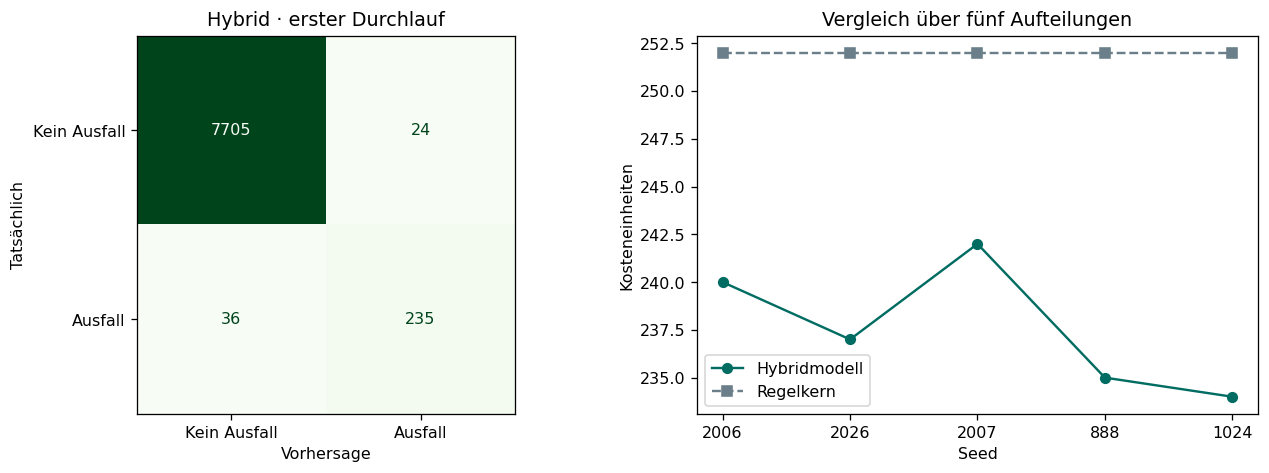

In [22]:
# Werte aus der berechneten Kreuzvalidierung übernehmen.
kosten = cv.pivot(index="Seed", columns="Modell", values="Kosten").loc[list(SEEDS)]
matrix = np.array([
    [erster_lauf["TN"], erster_lauf["FP"]],
    [erster_lauf["FN"], erster_lauf["TP"]],
])
if Figure is None:
    print("Für neu gerenderte Diagramme: %pip install matplotlib. Die Tabellen bleiben verfügbar.")
else:
    from sklearn.metrics import ConfusionMatrixDisplay

    # Links die Fehlertypen, rechts die Kostenstabilität auf denselben Seeds.
    fig = Figure(figsize=(11, 4), layout="constrained")
    axes = fig.subplots(1, 2)
    ConfusionMatrixDisplay(matrix, display_labels=["Kein Ausfall", "Ausfall"]).plot(
        ax=axes[0], colorbar=False, cmap="Greens", values_format="d"
    )
    axes[0].set(xlabel="Vorhersage", ylabel="Tatsächlich", title="Hybrid · erster Durchlauf")
    labels = [str(seed) for seed in SEEDS]
    axes[1].plot(labels, kosten["Hybrid"], "o-", color="#006C62", label="Hybridmodell")
    axes[1].plot(labels, kosten["Physikalische Regeln"], "s--", color="#6A7F8A", label="Regelkern")
    axes[1].set(xlabel="Seed", ylabel="Kosteneinheiten", title="Vergleich über fünf Aufteilungen")
    axes[1].legend()
    diagramm_anzeigen(fig)


## 7 · Interpretation der Alarmregeln

Für die abschließende Anwendung wird das festgelegte Modell auf allen beschrifteten Vorgängen trainiert. Die Tabelle dokumentiert die dabei geschätzten Alarmgrenzen. Bei der Kühlung gelten beide angegebenen Bedingungen gleichzeitig. Im Einsatz lässt sich je Alarm die ausgelöste Regel mit Messwert und Grenze dokumentieren. Bei einem zusätzlichen Verschleißalarm können Score und Schwelle protokolliert werden.

In [23]:
finales_modell = hybrid_trainieren(X, y)
(tief, hoch, delta, rpm, lastgrenzen), beginn, _ = finales_modell
grenzen_anzeigen = [
    ("Leistung unter [W]", tief), ("Leistung über [W]", hoch),
    ("Kühlung: Temperaturabstand unter [K]", delta), ("Kühlung: zugleich Drehzahl unter [U/min]", rpm),
    *[(f"Belastung Typ {typ} über [min × Nm]", lastgrenzen[code]) for typ, code in TYP.items()],
    ("Beginn des Verschleißeffekts [min]", beginn),
]
display(pd.DataFrame(grenzen_anzeigen, columns=["Merkmal", "Gelernte Grenze"]).round(2))

,Merkmal,Gelernte Grenze
0,Leistung unter [W],3500.0
1,Leistung über [W],9000.0
2,Kühlung: Temperaturabstand unter [K],8.6
3,Kühlung: zugleich Drehzahl unter [U/min],1380.0
4,Belastung Typ L über [min × Nm],11000.0
5,Belastung Typ M über [min × Nm],12000.0
6,Belastung Typ H über [min × Nm],13000.0
7,Beginn des Verschleißeffekts [min],200.0


## 8 · Challenge-Prognose und Kostenschätzung

Nach Abschluss des Trainings wird challenge.csv eingelesen. Der Export enthält ausschließlich die Spalte Machine failure und hält die Eingabereihenfolge ein. Die erwarteten Gesamtkosten ergeben sich aus den mittleren Validierungskosten je Vorgang, multipliziert mit der Zahl der Challenge-Vorgänge. Die Hochrechnung setzt vergleichbare Vorgänge voraus.

In [24]:
if not re.fullmatch(r"[\w -]+", GRUPPENNAME) or not GRUPPENNAME.strip():
    raise ValueError("Bitte einen gültigen Gruppennamen in der ersten Zelle eintragen.")
challenge = csv_lesen(DATENORDNER / "challenge.csv")
_, prognosen = vorhersagen(challenge, finales_modell)
AUSGABEORDNER.mkdir(parents=True, exist_ok=True)
datei = AUSGABEORDNER / f"challenge_prediction_{GRUPPENNAME}.csv"
pd.DataFrame({TARGET: prognosen}).to_csv(datei, index=False, lineterminator="\n")
kontrolle = pd.read_csv(datei)
assert list(kontrolle.columns) == [TARGET] and np.array_equal(kontrolle[TARGET], prognosen)

kosten_mittel = cv.loc[cv["Modell"] == "Hybrid", "Kosten"].mean()
erwartete_kosten = kosten_mittel / len(y) * len(challenge)
print(f"{datei} | {len(prognosen)} Vorhersagen | {prognosen.sum()} Alarme")
print(f"Geschätzte Challenge-Kosten: {erwartete_kosten:.1f}")

results\challenge_prediction_GRUPPENNAME.csv | 2000 Vorhersagen | 63 Alarme
Geschätzte Challenge-Kosten: 59.4


## Schlussfolgerungen

Das Hybridmodell erreicht **237,6 mittlere Kosteneinheiten**. Der reine Regelkern erreicht 252,0 und durchgehende Freigabe 1.626,0. Im gemeinsamen Referenzlauf senkt die Verschleißstufe die Kosten von 252 auf 240: Sie erkennt sechs zusätzliche Ausfälle bei 24 zusätzlichen Fehlalarmen.

Die Challenge-Prognose enthält **2.000 Vorgänge mit 63 Alarmen**. Die geschätzten Gesamtkosten betragen **59,4 Einheiten**. Für die betriebliche Einführung sind die dokumentierte Alarmbegründung und ein Schattenbetrieb sinnvoll. Im Schattenbetrieb lässt sich prüfen, ob die Vorwarnzeit für einen Eingriff ausreicht.

## Hilfsmittel
- OpenAI Codex, OpenAI, 18.11.2026. Unterstützung bei Umsetzung und Kommentierung des Notebooks sowie Redaktion der Erläuterungen. Siehe Hilfsmittelverzeichnis im Abgabepaket.